# Actividad Integradora 1 — Herramienta propia de EDA automatizado (AutoEDA)

**Asignatura:** Aplicaciones de Machine Learning · **Dataset:** `insurance.csv` (gastos médicos personales) · **Problema:** regresión con target continuo `charges`

## Objetivo de la actividad

Diseñar y programar una herramienta propia de EDA automatizado en Python que procese un dataset y genere, de forma **100 % automatizada**, un diagnóstico **estadístico, visual y de calidad de datos**, optimizado para identificar los problemas clave de los **modelos de regresión** —la **multicolinealidad**, el **sesgo** y los **valores atípicos**— cubriendo los **10 puntos de EDA** vistos en clase (archivo `Ejercicio`).

## Decisiones de diseño

- **Dataset:** `insurance.csv` (Kaggle, *Medical Cost Personal*): 1338 registros y 7 variables con target continuo → adecuado para regresión.
- **Arquitectura:** clase reutilizable `AutoEDA` (programación orientada a objetos), exportada con el comando mágico `%%writefile` al módulo `herramientas_eda.py`.
- **Referencia (benchmark):** `ydata-profiling` y `Sweetviz`, como pide el enunciado.
- **Principio metodológico:** la herramienta **solo diagnostica y reporta**. Ninguna alerta estadística se convierte en una decisión automática de limpieza: cada acción (eliminar, imputar, transformar) se propone como **recomendación para decisión humana** en la sección final de interpretación.

## Metodología unificada: los 10 puntos de EDA → métodos de la clase

| # | Punto de EDA | Operaciones clave | Método de `AutoEDA` |
|---|---|---|---|
| 1 | Importar librerías | pandas, numpy, matplotlib, seaborn + statsmodels (VIF) | Cabecera de `herramientas_eda.py` |
| 2 | Conocer el dataset | `head()`, `tail()`, `shape`, `sample()`, `columns`, `memory_usage` | `_paso2_conocer_dataset()` |
| 3 | Tipo de variable | `info()`, `dtypes`, `select_dtypes` | `_paso3_tipos_variable()` |
| 4 | Calidad de datos | `duplicated()`, valores raros (`?`, `-`, `N/A`, espacios) | `_paso4_calidad_datos()` |
| 5 | Valores faltantes | `isnull().sum()`, % de nulos, severidad | `_paso5_valores_faltantes()` |
| 6 | Outliers | boxplot, cuartiles, IQR | `_paso6_outliers()` |
| 7 | Estadística descriptiva | `describe()`, media, mediana, std, skew, kurtosis | `_paso7_estadistica_descriptiva()` |
| 8 | Desbalance de clases / target | `value_counts()`, porcentajes, `countplot` | `_paso8_target()` |
| 9 | Análisis univariado | histogramas, KDE, skew, curtosis | `_paso9_analisis_univariado()` |
| 10 | Bivariado / multivariado | scatter, boxplot por categoría, heatmap, **VIF** | `_paso10_bivariado_multivariado()` |

> **Orientación a regresión:** el punto 8 se adapta — si el target es continuo se analiza su distribución (media vs. mediana, skewness); si fuera categórico se analizaría el balance de clases con `value_counts()` + `countplot()`. El punto 10 agrega el **VIF** y los pares `|r| ≥ 0.80` para la multicolinealidad.

Todas las líneas de código de este cuaderno incluyen su **guía técnica de uso** como comentario.


## Punto 1 · Importar librerías (instalación e importación)

**Guía técnica de cada dependencia:**

- **pandas** — carga y manipulación tabular (`read_csv`, `DataFrame`, `Series`, `select_dtypes`).
- **numpy** — tipos numéricos y álgebra vectorizada (base de pandas).
- **matplotlib** — motor de renderizado de figuras (`subplots`, `show`, `tight_layout`).
- **seaborn** — gráficos estadísticos sobre matplotlib (`histplot`, `boxplot`, `heatmap`, `regplot`, `countplot`).
- **statsmodels** — cálculo del **VIF** (Factor de Inflación de la Varianza) para diagnosticar multicolinealidad.
- **ydata-profiling** y **sweetviz** — herramientas consolidadas de EDA automático usadas como **referencia comparativa (benchmark)** al final.


In [1]:
# PUNTO 1 — Instalación de dependencias (una por línea, -q silencia la salida de pip)
!pip install ydata-profiling -q   # herramienta de referencia: reporte EDA automático en HTML
!pip install sweetviz -q          # herramienta de referencia: reporte comparativo centrado en el target
!pip install statsmodels -q       # cálculo del VIF (multicolinealidad) y estadística inferencial
!pip install ipywidgets -q        # widgets de Jupyter: evita el aviso 'IProgress not found' de tqdm al importar ydata-profiling


In [2]:
# PUNTO 1 — Importación de librerías principales (cada import se explica con su rol técnico)
import warnings                                     # módulo estándar: controla qué avisos de Python se muestran
warnings.filterwarnings('ignore', category=DeprecationWarning, message='(?s).*ydata_profiling.*')  # silencia solo la nota de deprecación: '(?s)' activa DOTALL porque el mensaje inicia con un salto de línea y '.' no lo cruza por defecto
# se conserva 'ydata-profiling' a propósito: el enunciado de la actividad la pide explícitamente como herramienta de referencia  # silencia solo la nota de deprecación: el enunciado pide 'ydata-profiling' explícitamente, por eso se conserva a propósito
import pandas as pd                                  # pd: estructuras tabulares DataFrame/Series y lectura de CSV
import numpy as np                                   # np: tipos numéricos base y funciones matemáticas vectorizadas
import matplotlib.pyplot as plt                      # plt: creación y control de figuras (subplots, títulos, show)
import seaborn as sns                                # sns: gráficos estadísticos de alto nivel sobre matplotlib
# comando mágico de IPython: incrusta las figuras dentro del notebook (los magics de línea no aceptan comentario en su misma línea)
%matplotlib inline
from ydata_profiling import ProfileReport            # ProfileReport: reporte EDA automático de referencia (benchmark)
import sweetviz as sv                                # sv: reporte comparativo automatizado de Sweetviz (benchmark)

print("✓ Entorno configurado: pandas, numpy, matplotlib, seaborn, statsmodels, ydata-profiling y sweetviz.")  # confirmación visual de que el entorno quedó listo


✓ Entorno configurado: pandas, numpy, matplotlib, seaborn, statsmodels, ydata-profiling y sweetviz.


## Punto 2 · Conocer el dataset: carga y justificación

**Dataset:** `insurance.csv` — gastos médicos personales anuales (dataset clásico de Kaggle, *Medical Cost Personal*), servido desde un repositorio público.

**¿Por qué es apropiado para regresión?**

- Tiene un **target continuo** (`charges`: gasto médico anual) — requisito del enunciado.
- Combina **4 variables numéricas** (`age`, `bmi`, `children`, `charges`) y **3 categóricas** (`sex`, `smoker`, `region`): cobertura completa de los 10 puntos.
- Es compacto (1338 × 7): el diagnóstico propio y los benchmark corren rápido y el cuaderno es **reproducible sin adjuntar archivos** (descarga directa por URL).


In [3]:
# PUNTO 2 — Descarga y carga del dataset en un DataFrame de pandas
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"  # URL pública del archivo CSV
df = pd.read_csv(url)                                  # read_csv(): lee el CSV (remoto) y construye el DataFrame detectando tipos

# Declaración de la variable objetivo (dependiente) del problema de regresión
target_col = "charges"                                 # 'charges' = gasto médico anual: variable continua a predecir

# Verificación inmediata de la carga: dimensiones esperadas y vista previa del contenido
print(f"Dataset cargado con éxito. Dimensiones: {df.shape}")  # .shape → tupla (filas, columnas) esperada: (1338, 7)
df.head()                                              # head(): primeras 5 filas para validar formato y semántica de cada columna


Dataset cargado con éxito. Dimensiones: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Construcción de la herramienta: clase `AutoEDA` + `%%writefile`

**Diseño (programación orientada a objetos, reutilizable):**

- `__init__(df, target_col=None)` guarda una **copia** del DataFrame (`df.copy()`): los diagnósticos jamás mutan los datos del usuario.
- Un **método privado por punto de EDA** (`_paso2_...` a `_paso10_...`): cada uno imprime tablas y gráficos y registra sus hallazgos en una **bitácora** (`self.hallazgos`).
- `run_analysis()` ejecuta los 10 puntos **en orden con una sola llamada** → automatización 100 %.
- `obtener_hallazgos()` devuelve la bitácora como `DataFrame`: insumo directo de la sección final de interpretación.

**Lenguaje de reporte (requisito clave de la actividad):**

> Las alertas estadísticas (duplicados, nulos, outliers, sesgo, VIF) se emiten como **🔎 OBSERVACIÓN** con su evidencia numérica y las opciones a *evaluar*. La clase **nunca** elimina filas, imputa valores ni transforma variables por su cuenta: toda limpieza es una **decisión humana documentada** en la sección final.

**`%%writefile`** es un comando mágico de Jupyter/Colab que escribe el contenido completo de la celda en un archivo `.py` del entorno de ejecución; así la clase queda empaquetada y reutilizable en cualquier proyecto (`from herramientas_eda import AutoEDA`).


In [4]:
%%writefile herramientas_eda.py
# -*- coding: utf-8 -*-
"""
herramientas_eda.py — Actividad Integradora 1 · Aplicaciones de Machine Learning
================================================================================
Herramienta PROPIA de Análisis Exploratorio de Datos (EDA) 100 % automatizada,
orientada a modelos de REGRESIÓN. Cubre los 10 puntos de EDA de clase y emite un
diagnóstico estadístico, visual y de calidad de datos para detectar:

  · MULTICOLINEALIDAD  → matriz de correlación de Pearson + VIF (statsmodels).
  · SESGO (bias)       → skewness y curtosis de predictores y del target.
  · VALORES ATÍPICOS   → regla del rango intercuartílico (IQR) de Tukey + boxplots.

⚠️  PRINCIPIO METODOLÓGICO (lectura obligatoria antes de usar):
Esta clase SOLO DIAGNOSTICA Y REPORTA. Nunca elimina filas, imputa nulos ni
transforma variables de forma automática. Toda alerta estadística se presenta
como una OBSERVACIÓN (🔎) cuya acción de limpieza corresponde decidir al
analista, de forma documentada y con criterio de negocio.
"""

# ================== PASO 1. IMPORTAR LIBRERÍAS ==================
import math                                                     # módulo estándar: provee math.ceil() para calcular filas de subgráficos
import pandas as pd                                             # pandas: estructuras tabulares (DataFrame/Series) y operaciones vectorizadas
import numpy as np                                              # numpy: tipos numéricos base y funciones de álgebra/matemáticas
import matplotlib.pyplot as plt                                 # matplotlib: motor de renderizado de figuras (se usa el submódulo pyplot)
import seaborn as sns                                           # seaborn: gráficos estadísticos de alto nivel (histplot, boxplot, heatmap...)

try:                                                            # bloque tolerante: si statsmodels no está instalado, el resto de la clase sigue operativo
    from statsmodels.stats.outliers_influence import variance_inflation_factor  # statsmodels: función VIF para diagnosticar multicolinealidad
except ImportError:                                             # se captura la ausencia del paquete para degradar con elegancia (sin romper el EDA)
    variance_inflation_factor = None                            # marcador None: los métodos de VIF avisarán que el paquete no está disponible

# Constantes de los criterios estadísticos usados como umbrales de OBSERVACIÓN
UMBRAL_SKEW = 1.0      # |skewness| > 1.0  → distribución asimétrica que conviene evaluar (no transformar automáticamente)
UMBRAL_CORR = 0.80     # |r de Pearson| >= 0.80 → par de predictores con correlación lineal alta
UMBRAL_VIF_MOD = 5.0   # VIF > 5  → indicio moderado de multicolinealidad
UMBRAL_VIF_ALTO = 10.0 # VIF > 10 → indicio severo de multicolinealidad
MULTIPLO_IQR = 1.5     # factor de Tukey: Q1 - 1.5·IQR y Q3 + 1.5·IQR delimitan los valores "atípicos leves"
MULTIPLO_IQR_EXTREMO = 3.0  # factor 3.0·IQR delimita los valores "atípicos extremos"


def _mostrar(objeto):
    """Muestra un DataFrame/objeto con la representación enriquecida si está disponible (notebook) o texto plano (script)."""
    try:                                                        # intenta primero el camino interactivo de Jupyter/Colab
        from IPython.display import display                     # display() renderiza tablas HTML interactivas dentro del notebook
        display(objeto)                                         # despliega el objeto usando su representación gráfica nativa
    except ImportError:                                         # fuera de un notebook no existe IPython.display
        print(objeto)                                           # respaldo textual: print() funciona en cualquier entorno Python


class AutoEDA:
    """Clase reutilizable que ejecuta los 10 puntos de EDA de clase sobre un DataFrame, sin modificar los datos originales."""

    def __init__(self, df, target_col=None, figsize=(10, 6)):
        """Constructor: recibe el DataFrame y (opcionalmente) el nombre de la variable objetivo.

        Parámetros
        ----------
        df : pd.DataFrame
            Dataset a diagnosticar. Se trabaja sobre una COPIA para no mutar los datos del usuario.
        target_col : str, opcional
            Nombre de la variable dependiente (target). Si es numérica se asume un problema de REGRESIÓN.
        figsize : tuple, opcional
            Tamaño (ancho, alto) en pulgadas de las figuras de matplotlib.
        """
        self.df = df.copy()                                     # copia defensiva: ningún método de la clase altera el DataFrame original
        self.target_col = target_col                            # guarda el nombre del target para los análisis bivariados (puntos 8 y 10)
        self.figsize = figsize                                  # guarda el tamaño por defecto de las figuras generadas
        self.num_cols = self.df.select_dtypes(include=[np.number]).columns.tolist()   # columnas numéricas: enteros y flotantes (incluye booleanos 0/1)
        self.cat_cols = self.df.select_dtypes(include=['object', 'string', 'category']).columns.tolist()  # columnas categóricas/texto
        self.hallazgos = []                                     # bitácora: aquí se registran todas las OBSERVACIONES para la interpretación final

    # ----------------------------------------------------------------
    def _registrar(self, punto, tipo, detalle):
        """Registra una observación en la bitácora interna y la imprime con formato consistente.

        Parámetros
        ----------
        punto : int
            Número del punto de EDA (2 a 10) al que pertenece la observación.
        tipo : str
            Etiqueta corta de la observación (ej.: 'outliers', 'sesgo', 'multicolinealidad').
        detalle : str
            Texto explicativo con la evidencia numérica y la acción a EVALUAR (no a ejecutar).
        """
        self.hallazgos.append({'punto': punto, 'tipo': tipo, 'detalle': detalle})  # almacena la observación para el resumen final
        print(f"🔎 OBSERVACIÓN [P{punto} · {tipo}]: {detalle}")                     # imprime la observación: es un aviso, NUNCA una acción automática

    # ================== PASO 2. CONOCER EL DATASET ==================
    def _paso2_conocer_dataset(self):
        """Punto 2 — Conocer el dataset: dimensiones, memoria, catálogo de columnas y muestras (head/tail/sample)."""
        print("\n=== PASO 2. CONOCER EL DATASET ===")           # encabezado del bloque para lectura ágil del reporte
        print(f"Dimensiones: {self.df.shape[0]} filas × {self.df.shape[1]} columnas")   # .shape devuelve (n_filas, n_columnas)
        print(f"Memoria RAM estimada: {self.df.memory_usage(deep=True).sum() / 1024:.2f} KB")  # deep=True mide también los objetos internos de las cadenas
        print(f"Catálogo de columnas ({len(self.df.columns)}): {self.df.columns.tolist()}")     # .columns lista los nombres de todas las variables
        print("--- Primeras 3 filas (head) ---")                # head() inspecciona el inicio del dataset
        _mostrar(self.df.head(3))                               # muestra las 3 primeras filas para validar formato y semántica
        print("--- Últimas 3 filas (tail) ---")                 # tail() inspecciona el final (detecta registros truncados o mal cargados)
        _mostrar(self.df.tail(3))                               # muestra las 3 últimas filas
        print("--- Muestra aleatoria (sample) ---")             # sample() inspecciona filas al azar, útiles en datasets ordenados por fecha
        _mostrar(self.df.sample(3, random_state=42))            # random_state=42 fija la semilla para que la muestra sea reproducible

    # ================== PASO 3. TIPO DE VARIABLE ==================
    def _paso3_tipos_variable(self):
        """Punto 3 — Tipo de variable: clasifica cada columna (numérica vs. categórica) mediante dtypes/select_dtypes."""
        print("\n=== PASO 3. TIPO DE VARIABLE ===")             # encabezado del bloque
        tabla_tipos = pd.DataFrame({                           # construye una tabla resumen de tipos
            'tipo': self.df.dtypes.astype(str),                 # .dtypes devuelve el tipo pandas de cada columna (int64, float64, object...)
            'valores_unicos': self.df.nunique(),                # .nunique() cuenta valores distintos: útil para detectar IDs de alta cardinalidad
            'faltantes': self.df.isnull().sum(),                # conteo rápido de nulos como vista previa del punto 5
        })
        _mostrar(tabla_tipos)                                   # muestra la tabla de tipos
        print(f"Numéricas ({len(self.num_cols)}): {self.num_cols}")   # num_cols se calculó con select_dtypes(include=[np.number])
        print(f"Categóricas ({len(self.cat_cols)}): {self.cat_cols}") # cat_cols se calculó con select_dtypes(include=['object','string','category'])
        for c in self.cat_cols:                                 # recorre las categóricas buscando identificadores
            if self.df[c].nunique() == len(self.df):            # si hay tantos valores únicos como filas, la columna identifica cada registro
                self._registrar(3, 'identificador',             # registra la observación en la bitácora
                                f"'{c}' tiene {self.df[c].nunique()} valores únicos (uno por fila): "
                                f"evaluar si es un ID sin valor predictivo.")

    # ================== PASO 4. CALIDAD DE DATOS ==================
    def _paso4_calidad_datos(self):
        """Punto 4 — Calidad de datos: duplicados exactos y valores centinela ('?', '-', 'N/A', espacios sobrantes)."""
        print("\n=== PASO 4. CALIDAD DE DATOS ===")             # encabezado del bloque
        n_dup = self.df.duplicated().sum()                      # .duplicated() marca las filas idénticas a una anterior; .sum() las cuenta
        print(f"Filas duplicadas exactas: {n_dup} ({100 * n_dup / len(self.df):.2f}%)")  # porcentaje sobre el total de filas
        if n_dup > 0:                                           # solo emite observación si realmente existen duplicados
            self._registrar(4, 'duplicados',                    # registra la observación (no los elimina: decisión humana)
                            f"{n_dup} filas duplicadas detectadas: evaluar si se eliminan con "
                            f"df.drop_duplicates() o si corresponden a registros legítimos repetidos.")
        centinelas = ['?', '-', 'n/a', 'na', 'none', 'null', '']  # lista de valores típicos que "disfrazan" datos ausentes
        for c in self.cat_cols:                                 # la búsqueda de centinelas se aplica a columnas de texto
            normalizada = self.df[c].astype(str).str.strip().str.lower()  # convierte a texto, quita espacios y pasa a minúsculas para comparar
            n_raros = normalizada.isin(centinelas).sum()        # cuenta coincidencias exactas con los valores centinela
            n_espacios = (self.df[c].astype(str) != self.df[c].astype(str).str.strip()).sum()  # detecta textos con espacios al inicio o final
            if n_raros > 0 or n_espacios > 0:                   # si hay hallazgos en esta columna...
                self._registrar(4, 'valores_raros',             # ...se registra la observación con el detalle numérico
                                f"'{c}': {n_raros} valor(es) centinela ('?', '-', 'N/A'...) y "
                                f"{n_espacios} texto(s) con espacios sobrantes: evaluar normalización manual.")
            else:                                               # si la columna está limpia...
                print(f"✓ '{c}': sin valores centinela ni espacios sobrantes.")  # ...se reporta explícitamente como verificada

    # ================== PASO 5. VALORES FALTANTES ==================
    def _paso5_valores_faltantes(self):
        """Punto 5 — Valores faltantes: conteo, porcentaje y clasificación de severidad (sin imputar nada)."""
        print("\n=== PASO 5. VALORES FALTANTES ===")            # encabezado del bloque
        nulos = self.df.isnull().sum()                          # .isnull() marca cada celda vacía; .sum() cuenta los nulos por columna
        pct = (nulos / len(self.df)) * 100                      # convierte el conteo a porcentaje sobre el total de filas
        tabla_nulos = pd.DataFrame({'nulos': nulos, 'porcentaje(%)': pct.round(2)})  # tabla resumen ordenable por severidad
        _mostrar(tabla_nulos)                                   # muestra la tabla completa de nulos
        for c in self.df.columns:                               # recorre todas las columnas del dataset
            if nulos[c] > 0:                                    # solo clasifica las columnas que tienen nulos
                if pct[c] < 5:                                  # umbral 1: menos del 5 % de nulos
                    severidad = 'baja → evaluar imputación simple (media/mediana/moda)'
                elif pct[c] <= 30:                              # umbral 2: entre 5 % y 30 % de nulos
                    severidad = 'media → evaluar imputación avanzada o modelado específico'
                else:                                           # más del 30 % de nulos
                    severidad = 'alta → evaluar descarte de la columna o tratamiento especial'
                self._registrar(5, 'nulos',                     # registra la observación indicando severidad y opciones a EVALUAR
                                f"'{c}': {nulos[c]} nulos ({pct[c]:.2f}%) → severidad {severidad}. "
                                f"La herramienta NO imputa: la estrategia la define el analista.")
        if nulos.sum() == 0:                                    # caso más frecuente en datasets limpios
            print("✓ No se detectaron valores nulos (NaN/None): no se requiere estrategia de imputación.")  # confirma la ausencia de nulos

    # ================== PASO 6. OUTLIERS ==================
    def _paso6_outliers(self):
        """Punto 6 — Outliers: regla del IQR de Tukey (1.5× y 3.0×) sobre cada variable numérica + boxplots."""
        print("\n=== PASO 6. OUTLIERS (REGLA DEL IQR) ===")     # encabezado del bloque
        filas = []                                              # acumulador de resúmenes por variable
        for c in self.num_cols:                                 # la regla del IQR solo aplica a variables numéricas
            q1 = self.df[c].quantile(0.25)                      # primer cuartil Q1: valor bajo el cual queda el 25 % de los datos
            q3 = self.df[c].quantile(0.75)                      # tercer cuartil Q3: valor bajo el cual queda el 75 % de los datos
            iqr = q3 - q1                                       # rango intercuartílico: dispersión del 50 % central
            lim_inf = q1 - MULTIPLO_IQR * iqr                   # límite inferior de Tukey (1.5 × IQR)
            lim_sup = q3 + MULTIPLO_IQR * iqr                   # límite superior de Tukey (1.5 × IQR)
            n_out = ((self.df[c] < lim_inf) | (self.df[c] > lim_sup)).sum()   # cuenta valores fuera del intervalo [lim_inf, lim_sup]
            n_ext = ((self.df[c] < q1 - MULTIPLO_IQR_EXTREMO * iqr) |        # umbral 3.0 × IQR para atípicos extremos
                     (self.df[c] > q3 + MULTIPLO_IQR_EXTREMO * iqr)).sum()
            filas.append({'variable': c, 'Q1': round(q1, 2), 'Q3': round(q3, 2), 'IQR': round(iqr, 2),
                          'atipicos': n_out, 'atipicos_%': round(100 * n_out / len(self.df), 2),
                          'extremos': n_ext})                    # agrega el resumen de la variable a la lista
            if n_out > 0:                                       # emite observación solo si la variable tiene atípicos
                self._registrar(6, 'outliers',                  # registra la observación: sugiere VERIFICAR, nunca borrar
                                f"'{c}': {n_out} valores atípicos ({100 * n_out / len(self.df):.2f}%) y {n_ext} extremos. "
                                f"Verificar si son anomalías reales o errores de captura antes de decidir su tratamiento.")
        _mostrar(pd.DataFrame(filas))                           # muestra la tabla resumen de outliers
        ncols = 3                                               # número de boxplots por fila en la cuadrícula
        nrows = math.ceil(len(self.num_cols) / ncols)           # calcula cuántas filas de subgráficos se necesitan
        fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))  # crea la cuadrícula de ejes
        axes = axes.flatten()                                   # convierte la matriz de ejes en lista plana para iterar fácil
        for i, c in enumerate(self.num_cols):                   # recorre cada variable numérica con su subgráfico
            sns.boxplot(data=self.df, x=c, ax=axes[i])          # boxplot horizontal: mediana, caja Q1–Q3, bigotes y puntos atípicos
            axes[i].set_title(f'Boxplot de {c}')                # titula el subgráfico con el nombre de la variable
        for j in range(len(self.num_cols), len(axes)):          # recorre los ejes sobrantes (si sobran celdas en la cuadrícula)
            axes[j].axis('off')                                 # apaga los ejes vacíos para una figura limpia
        plt.tight_layout()                                      # ajusta márgenes para que títulos y etiquetas no se solapen
        plt.show()                                              # renderiza la figura (en notebook: salida en línea; en script: ventana/archivo)

    # ================== PASO 7. ESTADÍSTICA DESCRIPTIVA ==================
    def _paso7_estadistica_descriptiva(self):
        """Punto 7 — Estadística descriptiva: tendencia central, dispersión, asimetría y curtosis de las numéricas."""
        print("\n=== PASO 7. ESTADÍSTICA DESCRIPTIVA ===")      # encabezado del bloque
        if not self.num_cols:                                   # si no hay variables numéricas no hay nada que describir
            print("⚠ No hay variables numéricas en el dataset.")  # aviso explícito en lugar de fallar
            return                                              # termina el método sin error
        desc = self.df[self.num_cols].describe().T              # describe() calcula count, mean, std, min, cuartiles y max; .T transpone
        desc['rango'] = desc['max'] - desc['min']               # amplitud total: distancia entre el máximo y el mínimo
        desc['cv'] = desc.apply(                                # coeficiente de variación CV = std/media (dispersión relativa)
            lambda fila: (fila['std'] / fila['mean']) if fila['mean'] != 0 else np.nan,  # evita dividir entre cero cuando media=0
            axis=1).round(2)                                    # axis=1 aplica la función fila por fila; .round(2) limita decimales
        desc['skewness'] = self.df[self.num_cols].skew().round(2)   # skew(): asimetría muestral (>0 cola derecha, <0 cola izquierda)
        desc['curtosis'] = self.df[self.num_cols].kurt().round(2)   # kurt(): curtosis EXCESIVA (0 = normal; >0 colas pesadas)
        _mostrar(desc[['mean', 'std', 'min', '50%', 'max', 'rango', 'cv', 'skewness', 'curtosis']])  # muestra las columnas relevantes
        print("· '50%' es la mediana (percentil 50): si difiere mucho de la media, la distribución está sesgada.")  # ayuda interpretativa

    # ================== PASO 8. DESBALANCE / TARGET ==================
    def _paso8_target(self):
        """Punto 8 — Variable objetivo: distribución (regresión, target continuo) o balance de clases (clasificación)."""
        print("\n=== PASO 8. VARIABLE OBJETIVO (TARGET) ===")   # encabezado del bloque
        if self.target_col is None:                             # la clase también debe funcionar sin target (análisis exploratorio puro)
            print("ℹ No se declaró target_col: se omite el punto 8 (pasar target_col='nombre' al instanciar).")
            return                                              # termina el método sin error
        if self.target_col not in self.df.columns:              # valida que el nombre del target exista realmente en el DataFrame
            print(f"⚠ El target '{self.target_col}' no existe entre las columnas: {self.df.columns.tolist()}")
            return                                              # termina el método sin error
        if self.target_col in self.num_cols:                    # RAMA REGRESIÓN: el target es continuo
            s = self.df[self.target_col]                        # Serie con los valores del target
            print(f"Target continuo '{self.target_col}': media={s.mean():.2f} · mediana={s.median():.2f} · "
                  f"min={s.min():.2f} · max={s.max():.2f} · skew={s.skew():.2f}")  # resumen de forma y ubicación
            if abs(s.skew()) > UMBRAL_SKEW:                     # compara la asimetría con el umbral de observación
                self._registrar(8, 'sesgo_target',              # registra la observación sobre el target
                                f"El target '{self.target_col}' tiene |skew|={abs(s.skew()):.2f} > {UMBRAL_SKEW}: "
                                f"la media se aleja de la mediana. Evaluar transformación log(1+x) o Box-Cox "
                                f"SOLO si el modelo lo requiere (decisión humana, no automática).")
            plt.figure(figsize=self.figsize)                    # crea una figura nueva con el tamaño por defecto
            sns.histplot(s, kde=True, bins=30)                  # histograma con curva de densidad KDE: revela la forma de la distribución
            plt.axvline(s.mean(), color='red', linestyle='--', label=f'media={s.mean():.0f}')    # línea vertical en la media
            plt.axvline(s.median(), color='green', linestyle='--', label=f'mediana={s.median():.0f}')  # línea vertical en la mediana
            plt.title(f'Distribución del target: {self.target_col}')  # título descriptivo de la figura
            plt.legend()                                        # muestra la leyenda con media y mediana
            plt.show()                                          # renderiza la figura
        else:                                                   # RAMA CLASIFICACIÓN: el target es categórico
            conteos = self.df[self.target_col].value_counts(normalize=True) * 100  # value_counts(normalize=True) devuelve proporciones por clase
            print(f"Distribución de clases del target '{self.target_col}' (%):")  # encabezado de la tabla de balance
            _mostrar(conteos.round(2))                          # muestra los porcentajes de cada clase
            if conteos.min() < 20:                              # regla práctica: clase minoritaria por debajo del 20 % = desbalance
                self._registrar(8, 'desbalance',                # registra la observación de desbalance
                                f"La clase minoritaria '{conteos.idxmin()}' representa {conteos.min():.1f}%: "
                                f"evaluar técnicas de balanceo (SMOTE, class_weight) según el modelo elegido.")
            plt.figure(figsize=self.figsize)                    # crea la figura
            sns.countplot(data=self.df, x=self.target_col)      # countplot: barras con la frecuencia de cada clase
            plt.title(f'Balance de clases: {self.target_col}')  # título de la figura
            plt.show()                                          # renderiza la figura

    # ================== PASO 9. ANÁLISIS UNIVARIADO ==================
    def _paso9_analisis_univariado(self):
        """Punto 9 — Análisis univariado: histogramas + KDE y diagnóstico de sesgo (skewness) y curtosis por variable."""
        print("\n=== PASO 9. ANÁLISIS UNIVARIADO (DISTRIBUCIONES) ===")  # encabezado del bloque
        if not self.num_cols:                                   # guarda: sin numéricas no aplica
            print("⚠ No hay variables numéricas en el dataset.")
            return                                              # termina el método sin error
        tabla_forma = pd.DataFrame({                           # tabla comparativa de forma de cada distribución
            'skewness': self.df[self.num_cols].skew().round(2),     # asimetría por variable
            'curtosis': self.df[self.num_cols].kurt().round(2),     # curtosis excesiva por variable
        })
        _mostrar(tabla_forma)                                   # muestra la tabla de forma
        for c in self.num_cols:                                 # recorre cada variable numérica
            if abs(tabla_forma.loc[c, 'skewness']) > UMBRAL_SKEW:  # aplica el umbral de sesgo severo
                self._registrar(9, 'sesgo',                     # registra la observación de asimetría
                                f"'{c}': |skew|={abs(tabla_forma.loc[c, 'skewness']):.2f} > {UMBRAL_SKEW} → "
                                f"distribución asimétrica. Evaluar transformación (log(1+x), Box-Cox) según el modelo: "
                                f"no es una acción automática.")
        ncols = 3                                               # número de histogramas por fila
        nrows = math.ceil(len(self.num_cols) / ncols)           # filas necesarias de la cuadrícula
        fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))  # crea la cuadrícula de ejes
        axes = axes.flatten()                                   # aplana los ejes para iterar
        for i, c in enumerate(self.num_cols):                   # recorre cada variable con su subgráfico
            sns.histplot(self.df[c], kde=True, bins=30, ax=axes[i], color='skyblue')  # histograma + curva KDE de la variable
            axes[i].set_title(f'Distribución de {c} (skew={tabla_forma.loc[c, "skewness"]})')  # título con la asimetría
        for j in range(len(self.num_cols), len(axes)):          # apaga ejes sobrantes
            axes[j].axis('off')                                 # oculta celdas vacías de la cuadrícula
        plt.tight_layout()                                      # ajusta márgenes
        plt.show()                                              # renderiza la figura

    # ================== PASO 10. BIVARIADO / MULTIVARIADO ==================
    def _paso10_bivariado_multivariado(self):
        """Punto 10 — Bivariado/multivariado: relación con el target, correlación (heatmap) y multicolinealidad (VIF)."""
        print("\n=== PASO 10. ANÁLISIS BIVARIADO Y MULTIVARIADO ===")  # encabezado del bloque
        # --- 10a. Predictores NUMÉRICOS vs target: scatter con recta de tendencia ---
        if self.target_col and self.target_col in self.num_cols:  # solo aplica si hay target numérico declarado
            corr_target = self.df[self.num_cols].corr()[self.target_col].drop(self.target_col)  # correlación Pearson de cada numérica con el target
            corr_target = corr_target.sort_values(key=abs, ascending=False)  # ordena por valor absoluto: las más influyentes primero
            print(f"Correlación de Pearson de cada predictor numérico con '{self.target_col}':")  # encabezado del ranking
            _mostrar(corr_target.round(3))                      # muestra el ranking de correlaciones con el target
            for c in [x for x in self.num_cols if x != self.target_col]:  # recorre los predictores numéricos (excluye el target)
                plt.figure(figsize=self.figsize)                # figura por cada relación predictor–target
                sns.regplot(data=self.df, x=c, y=self.target_col,  # regplot: nube de puntos + recta de regresión lineal
                            scatter_kws={'alpha': 0.35},        # transparencia de los puntos para ver densidad
                            line_kws={'color': 'red'})          # recta de tendencia en rojo
                plt.title(f'{c} vs {self.target_col} (r={corr_target[c]:.3f})')  # título con el coeficiente de Pearson
                plt.show()                                      # renderiza la figura
        # --- 10b. Predictores CATEGÓRICOS vs target: boxplots agrupados ---
        if self.target_col and self.target_col in self.df.columns:  # aplica a cualquier target declarado (numérico o categórico)
            for c in self.cat_cols:                             # recorre cada variable categórica
                plt.figure(figsize=self.figsize)                # figura por categoría
                sns.boxplot(data=self.df, x=c, y=self.target_col)  # boxplot del target por cada categoría: revela efectos de grupo
                plt.title(f'{self.target_col} por {c}')         # título descriptivo
                plt.show()                                      # renderiza la figura
        # --- 10c. Matriz de correlación (heatmap) y pares colineales ---
        if len(self.num_cols) > 1:                              # se necesitan al menos 2 numéricas para correlacionar
            corr = self.df[self.num_cols].corr()                # matriz de correlación lineal de Pearson entre todas las numéricas
            plt.figure(figsize=(8, 6))                          # figura cuadrada para el heatmap
            sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',  # heatmap anotado: color frío para negativos, cálido para positivos
                        center=0, linewidths=0.5)               # center=0 ancla la escala de color en correlación nula
            plt.title('Matriz de correlación de Pearson (variables numéricas)')  # título del heatmap
            plt.tight_layout()                                  # ajusta márgenes
            plt.show()                                          # renderiza el heatmap
            for i in range(len(self.num_cols)):                 # doble bucle para revisar TODOS los pares sin repetir
                for j in range(i + 1, len(self.num_cols)):      # j inicia en i+1: solo la mitad triangular superior
                    v = corr.iloc[i, j]                         # coeficiente del par (i, j)
                    if abs(v) >= UMBRAL_CORR:                   # aplica el umbral de alta correlación
                        self._registrar(10, 'multicolinealidad',  # registra el par colineal como observación
                                        f"'{self.num_cols[i]}' y '{self.num_cols[j]}' con |r|={abs(v):.2f} ≥ {UMBRAL_CORR}: "
                                        f"evaluar eliminar una de las dos o combinarlas antes de un modelo lineal.")
            if not any(abs(corr.iloc[i, j]) >= UMBRAL_CORR      # verifica si NO hubo ningún par por encima del umbral
                       for i in range(len(self.num_cols)) for j in range(i + 1, len(self.num_cols))):
                print(f"✓ Ningún par de variables numéricas supera |r| = {UMBRAL_CORR}.")  # confirma ausencia de correlación extrema
        # --- 10d. VIF: Factor de Inflación de la Varianza ---
        if variance_inflation_factor is None:                   # si statsmodels no se instaló en el entorno...
            print("⚠ VIF no disponible: instala statsmodels (pip install statsmodels) para el diagnóstico de multicolinealidad.")
            return                                              # termina solo este bloque, no el resto del análisis
        predictores = [c for c in self.num_cols if c != self.target_col]  # excluye el target del cálculo de VIF
        if len(predictores) > 1:                                # el VIF exige al menos 2 predictores
            X = self.df[predictores].dropna()                   # VIF requiere matriz sin nulos ni constantes; dropna garantiza lo primero
            try:                                                # protege contra columnas constantes (varianza cero) que invalidan el VIF
                tabla_vif = pd.DataFrame({                      # construye la tabla de resultados
                    'variable': predictores,                    # nombre de cada predictor
                    'VIF': [round(variance_inflation_factor(X.values, i), 2) for i in range(len(predictores))],  # VIF_i = 1/(1-R²_i) de cada predictor frente a los demás
                })
                _mostrar(tabla_vif)                             # muestra la tabla VIF
                for i, c in enumerate(predictores):             # recorre los resultados para clasificar la severidad
                    if tabla_vif.loc[i, 'VIF'] > UMBRAL_VIF_ALTO:      # VIF > 10: multicolinealidad severa
                        self._registrar(10, 'vif',              # registra la observación severa
                                        f"'{c}': VIF={tabla_vif.loc[i, 'VIF']:.2f} > {UMBRAL_VIF_ALTO} → multicolinealidad severa: "
                                        f"evaluar eliminar la variable o combinarla con otra.")
                    elif tabla_vif.loc[i, 'VIF'] > UMBRAL_VIF_MOD:     # VIF entre 5 y 10: multicolinealidad moderada
                        self._registrar(10, 'vif',              # registra la observación moderada
                                        f"'{c}': VIF={tabla_vif.loc[i, 'VIF']:.2f} > {UMBRAL_VIF_MOD} → multicolinealidad moderada: "
                                        f"monitorear su efecto sobre los coeficientes del modelo.")
                if (tabla_vif['VIF'] <= UMBRAL_VIF_MOD).all():  # si todos los VIF quedan por debajo del umbral moderado
                    print(f"✓ VIF de todos los predictores ≤ {UMBRAL_VIF_MOD}: sin indicios de multicolinealidad.")  # confirma diagnóstico sano
            except ValueError:                                  # captura el caso de columnas constantes u otros fallos numéricos
                print("⚠ No se pudo calcular el VIF (posible columna constante o singularidad numérica).")  # aviso sin romper el flujo

    # ================== ORQUESTADOR PRINCIPAL ==================
    def run_analysis(self):
        """Método público: ejecuta los 10 puntos de EDA en orden y de forma 100 % automatizada (una sola llamada)."""
        print("=" * 72)                                         # línea separadora superior del reporte
        print(" DIAGNÓSTICO AUTOMATIZADO DE EDA · ORIENTADO A REGRESIÓN ".center(72))  # título centrado del reporte
        print("=" * 72)                                         # línea separadora
        print("⚠  Esta herramienta SOLO diagnostica y reporta: no elimina filas, no imputa")
        print("   nulos y no transforma variables. Cada acción de limpieza es una decisión")
        print("   HUMANA que debe documentarse en la sección de interpretación.\n")
        print("PASO 1 (importar librerías) se cumple en la cabecera de este módulo:")  # aclaración del punto 1
        print("pandas, numpy, matplotlib, seaborn y statsmodels (para el VIF).\n")
        self._paso2_conocer_dataset()                           # ejecuta el punto 2: conocer el dataset
        self._paso3_tipos_variable()                            # ejecuta el punto 3: tipo de variable
        self._paso4_calidad_datos()                             # ejecuta el punto 4: calidad de datos
        self._paso5_valores_faltantes()                         # ejecuta el punto 5: valores faltantes
        self._paso6_outliers()                                  # ejecuta el punto 6: outliers (IQR + boxplots)
        self._paso7_estadistica_descriptiva()                   # ejecuta el punto 7: estadística descriptiva
        self._paso8_target()                                    # ejecuta el punto 8: target / balance de clases
        self._paso9_analisis_univariado()                       # ejecuta el punto 9: análisis univariado
        self._paso10_bivariado_multivariado()                   # ejecuta el punto 10: bivariado/multivariado + VIF
        print("=" * 72)                                         # línea separadora inferior
        print(f" DIAGNÓSTICO COMPLETADO · {len(self.hallazgos)} observaciones registradas ".center(72))  # total de observaciones
        print("=" * 72)                                         # línea separadora
        print("Para la interpretación final ejecuta: eda.obtener_hallazgos()")  # indica cómo recuperar la bitácora

    def obtener_hallazgos(self):
        """Devuelve la bitácora completa de observaciones como DataFrame, insumo para la sección de interpretación."""
        if not self.hallazgos:                                  # caso sin observaciones registradas
            return pd.DataFrame(columns=['punto', 'tipo', 'detalle'])  # devuelve la tabla vacía con las mismas columnas
        return pd.DataFrame(self.hallazgos)                     # convierte la lista de dictados en un DataFrame tabular


Overwriting herramientas_eda.py


## Ejecución automatizada: los 10 puntos en una sola llamada

La celda siguiente demuestra la automatización exigida por el enunciado: **instanciar la clase y ejecutar `run_analysis()`**. Todo el diagnóstico (tablas, gráficos y observaciones) se genera sin intervención manual, y al final se recupera la bitácora `obtener_hallazgos()` como insumo para la interpretación.


        DIAGNÓSTICO AUTOMATIZADO DE EDA · ORIENTADO A REGRESIÓN         
⚠  Esta herramienta SOLO diagnostica y reporta: no elimina filas, no imputa
   nulos y no transforma variables. Cada acción de limpieza es una decisión
   HUMANA que debe documentarse en la sección de interpretación.

PASO 1 (importar librerías) se cumple en la cabecera de este módulo:
pandas, numpy, matplotlib, seaborn y statsmodels (para el VIF).


=== PASO 2. CONOCER EL DATASET ===
Dimensiones: 1338 filas × 7 columnas
Memoria RAM estimada: 255.18 KB
Catálogo de columnas (7): ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
--- Primeras 3 filas (head) ---


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.9240
1,18,male,33.77,1,no,southeast,1725.5523
2,28,male,33.00,3,no,southeast,4449.4620


--- Últimas 3 filas (tail) ---


,age,sex,bmi,children,smoker,region,charges
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


--- Muestra aleatoria (sample) ---


...

,tipo,valores_unicos,faltantes
age,int64,47,0
sex,object,2,0
bmi,float64,548,0
children,int64,6,0
smoker,object,2,0
region,object,4,0
charges,float64,1337,0


Numéricas (4): ['age', 'bmi', 'children', 'charges']
Categóricas (3): ['sex', 'smoker', 'region']

=== PASO 4. CALIDAD DE DATOS ===
Filas duplicadas exactas: 1 (0.07%)
🔎 OBSERVACIÓN [P4 · duplicados]: 1 filas duplicadas detectadas: evaluar si se eliminan con df.drop_duplicates() o si corresponden a registros legítimos repetidos.
✓ 'sex': sin valores centinela ni espacios sobrantes.
✓ 'smoker': sin valores centinela ni espacios sobrantes.
✓ 'region': sin valores centinela ni espacios sobrantes.

=== PASO 5. VALORES FALTANTES ===


,nulos,porcentaje(%)
age,0,0.0
sex,0,0.0
bmi,0,0.0
children,0,0.0
smoker,0,0.0
region,0,0.0
charges,0,0.0


✓ No se detectaron valores nulos (NaN/None): no se requiere estrategia de imputación.

=== PASO 6. OUTLIERS (REGLA DEL IQR) ===
🔎 OBSERVACIÓN [P6 · outliers]: 'bmi': 9 valores atípicos (0.67%) y 0 extremos. Verificar si son anomalías reales o errores de captura antes de decidir su tratamiento.
🔎 OBSERVACIÓN [P6 · outliers]: 'charges': 139 valores atípicos (10.39%) y 6 extremos. Verificar si son anomalías reales o errores de captura antes de decidir su tratamiento.


,variable,Q1,Q3,IQR,atipicos,atipicos_%,extremos
0,age,27.00,51.00,24.00,0,0.00,0
1,bmi,26.30,34.69,8.40,9,0.67,0
2,children,0.00,2.00,2.00,0,0.00,0
3,charges,4740.29,16639.91,11899.63,139,10.39,6


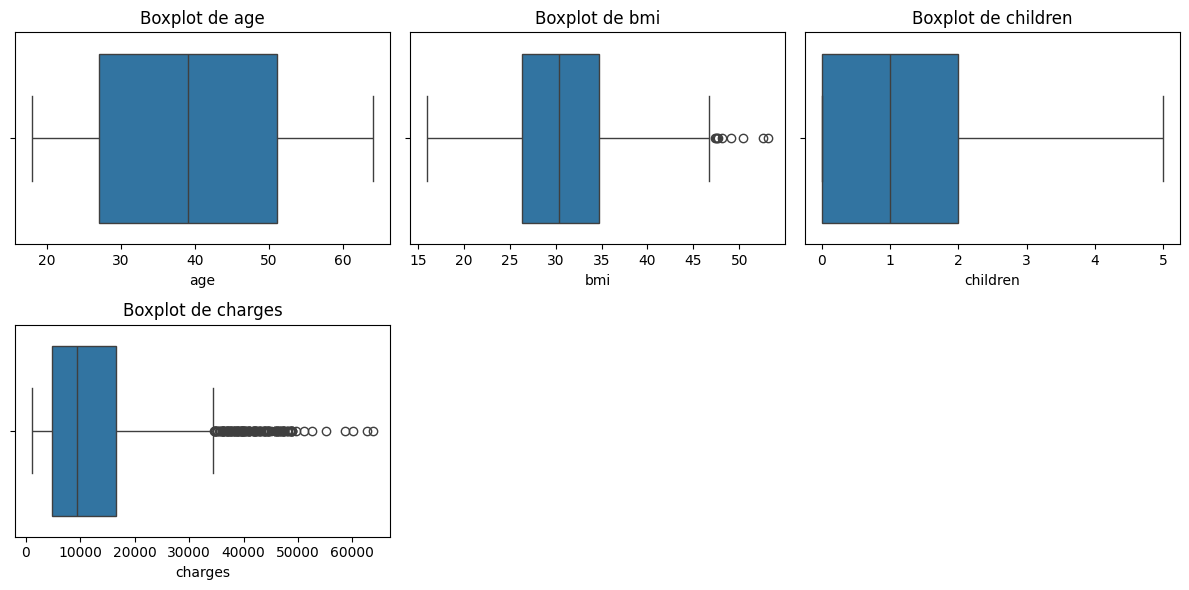


=== PASO 7. ESTADÍSTICA DESCRIPTIVA ===


,mean,std,min,50%,max,rango,cv,skewness,curtosis
age,39.207025,14.049960,18.0000,39.000,64.00000,46.00000,0.36,0.06,-1.25
bmi,30.663397,6.098187,15.9600,30.400,53.13000,37.17000,0.20,0.28,-0.05
children,1.094918,1.205493,0.0000,1.000,5.00000,5.00000,1.10,0.94,0.20
charges,13270.422265,12110.011237,1121.8739,9382.033,63770.42801,62648.55411,0.91,1.52,1.61


· '50%' es la mediana (percentil 50): si difiere mucho de la media, la distribución está sesgada.

=== PASO 8. VARIABLE OBJETIVO (TARGET) ===
Target continuo 'charges': media=13270.42 · mediana=9382.03 · min=1121.87 · max=63770.43 · skew=1.52
🔎 OBSERVACIÓN [P8 · sesgo_target]: El target 'charges' tiene |skew|=1.52 > 1.0: la media se aleja de la mediana. Evaluar transformación log(1+x) o Box-Cox SOLO si el modelo lo requiere (decisión humana, no automática).


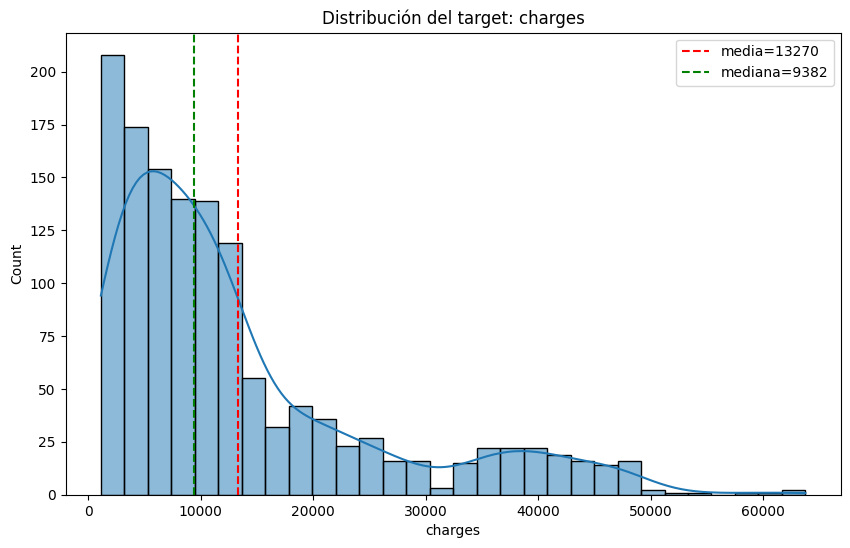


=== PASO 9. ANÁLISIS UNIVARIADO (DISTRIBUCIONES) ===


,skewness,curtosis
age,0.06,-1.25
bmi,0.28,-0.05
children,0.94,0.20
charges,1.52,1.61


🔎 OBSERVACIÓN [P9 · sesgo]: 'charges': |skew|=1.52 > 1.0 → distribución asimétrica. Evaluar transformación (log(1+x), Box-Cox) según el modelo: no es una acción automática.


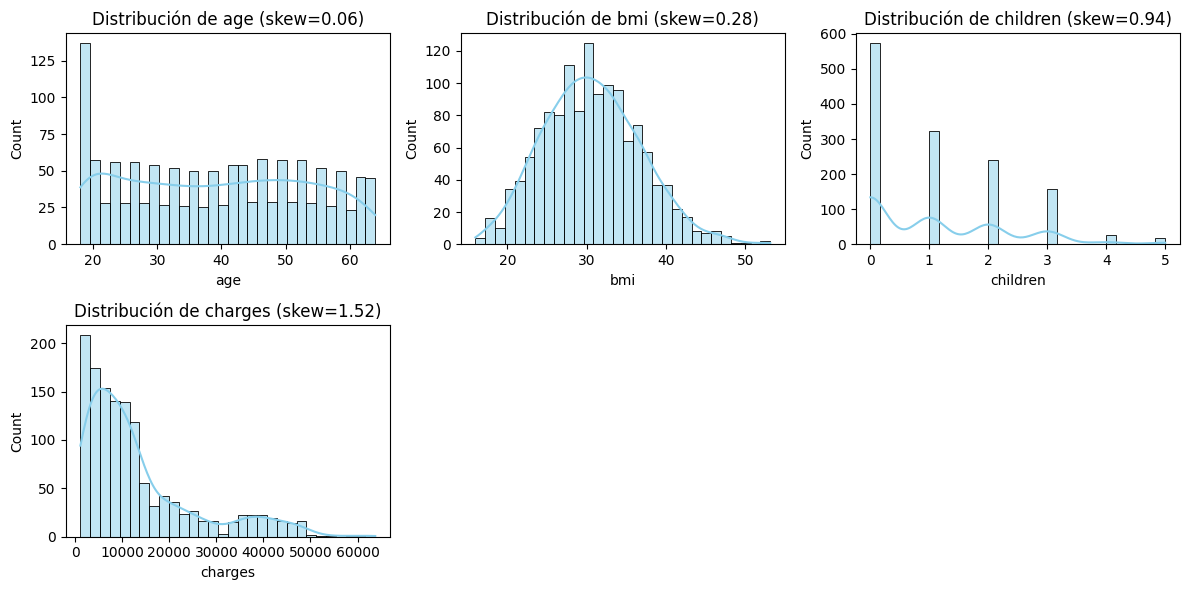


=== PASO 10. ANÁLISIS BIVARIADO Y MULTIVARIADO ===
Correlación de Pearson de cada predictor numérico con 'charges':


age         0.299
bmi         0.198
children    0.068
Name: charges, dtype: float64

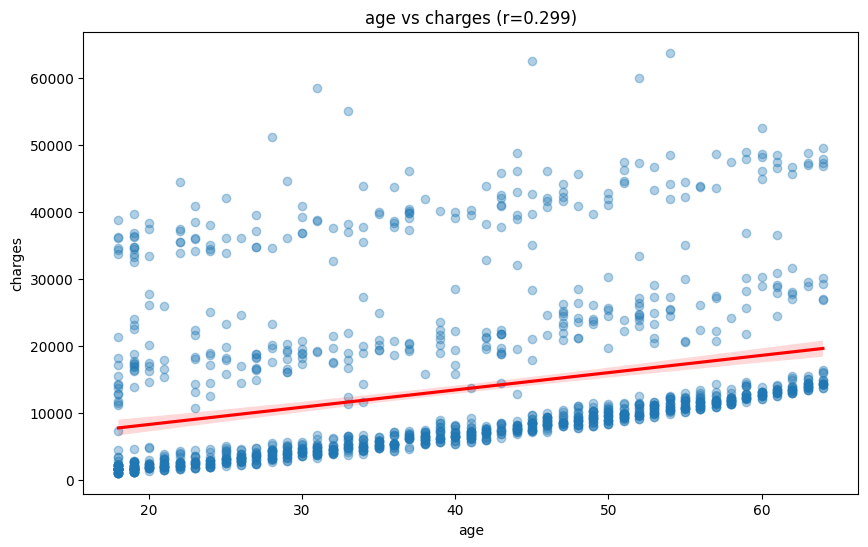

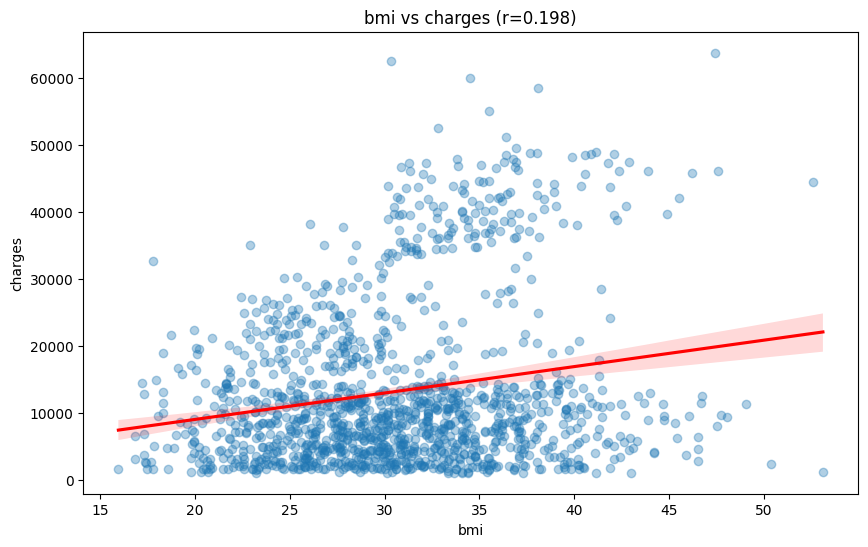

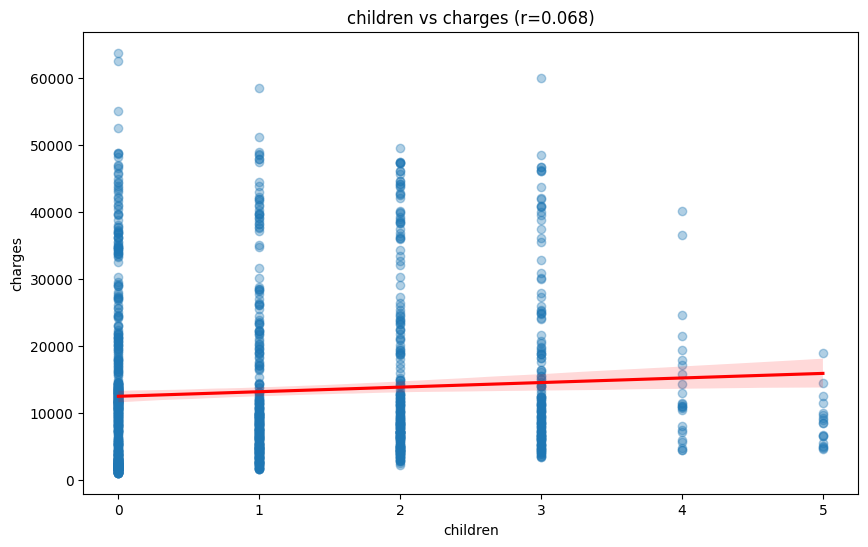

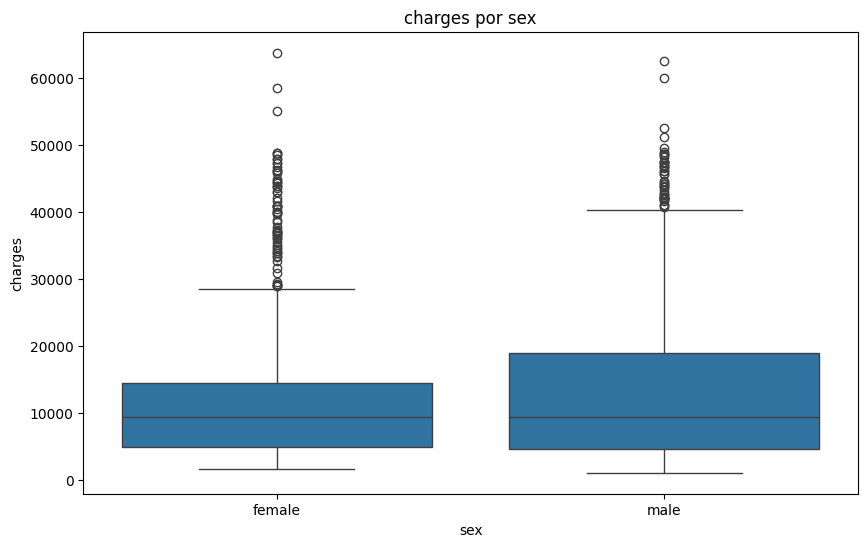

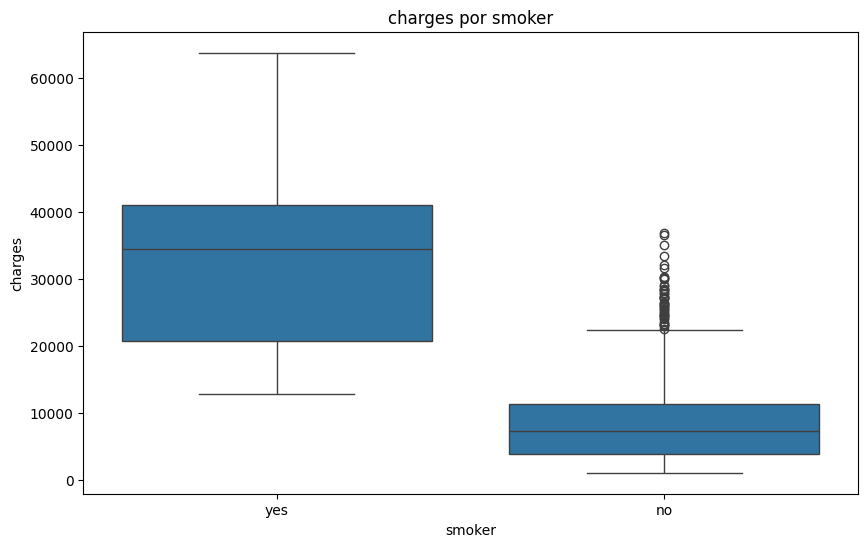

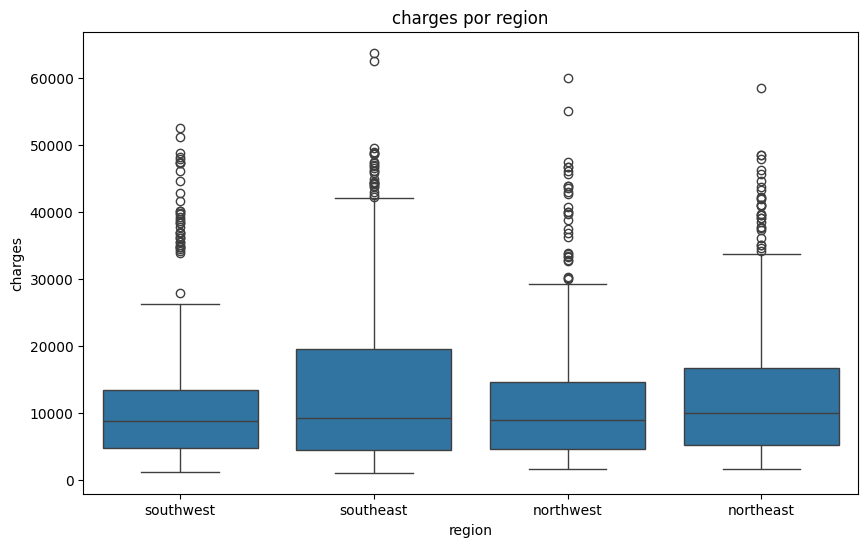

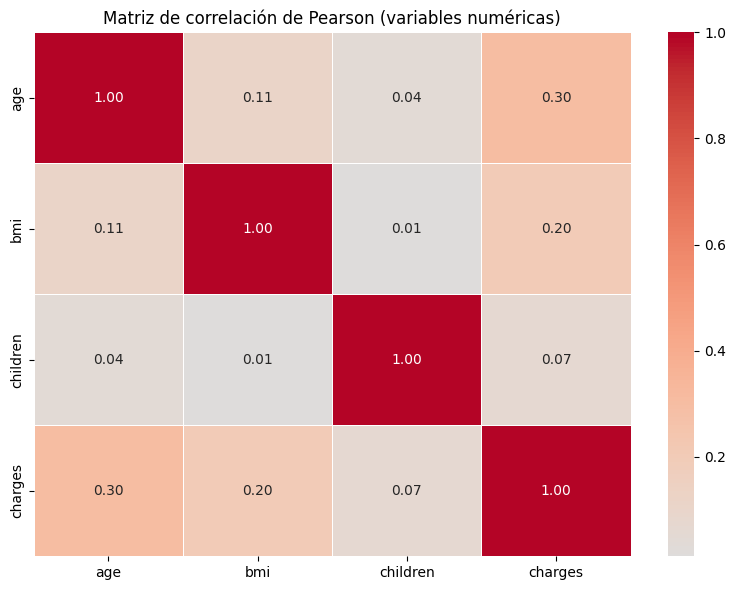

✓ Ningún par de variables numéricas supera |r| = 0.8.


,variable,VIF
0,age,1.01
1,bmi,1.01
2,children,1.00


✓ VIF de todos los predictores ≤ 5.0: sin indicios de multicolinealidad.
          DIAGNÓSTICO COMPLETADO · 5 observaciones registradas          
Para la interpretación final ejecuta: eda.obtener_hallazgos()


,punto,tipo,detalle
0,4,duplicados,1 filas duplicadas detectadas: evaluar si se e...
1,6,outliers,'bmi': 9 valores atípicos (0.67%) y 0 extremos...
2,6,outliers,'charges': 139 valores atípicos (10.39%) y 6 e...
3,8,sesgo_target,El target 'charges' tiene |skew|=1.52 > 1.0: l...
4,9,sesgo,'charges': |skew|=1.52 > 1.0 → distribución as...


In [5]:
# Importa la clase AutoEDA desde el módulo físico que generó %%writefile en la celda anterior
from herramientas_eda import AutoEDA               # importa la clase reutilizable (queda en la carpeta del notebook)

# Instancia la herramienta declarando el target continuo del problema de regresión
eda = AutoEDA(df, target_col=target_col)           # construye el objeto: copia el DataFrame y clasifica numéricas/categóricas

# Ejecuta los 10 puntos de EDA con UNA sola llamada (automatización 100 %)
eda.run_analysis()                                 # imprime el diagnóstico completo: tablas, gráficos y observaciones

# Recupera la bitácora de observaciones: insumo directo de la sección final de interpretación
eda.obtener_hallazgos()                            # DataFrame con columnas 'punto', 'tipo' y 'detalle' de cada observación


## Referencia comparativa (benchmark): ydata-profiling y Sweetviz

El enunciado pide revisar `ydata-profiling` y `Sweetviz` como herramientas de EDA automático de referencia. La celda siguiente genera sus reportes HTML para **validar que los hallazgos de `AutoEDA` coinciden** con los de las herramientas consolidadas (nulos, correlaciones, distribuciones, outliers, relación con el target).


In [6]:
# BENCHMARK — Reporte de ydata-profiling: perfil completo de calidad y distribuciones
profile = ProfileReport(df, title="Diagnóstico ydata-profiling — insurance.csv", explorative=True)  # construye el perfil automático en modo exploratorio
profile.to_file("diagnostico_ydata.html")          # exporta el perfil a un archivo HTML navegable (se abre en el navegador)

# BENCHMARK — Reporte de Sweetviz: informe comparativo centrado en el target y sus relaciones
reporte_sv = sv.analyze(df, target_feat=target_col)  # analyze(): genera el informe tomando 'charges' como variable objetivo
reporte_sv.show_html("reporte_sweetviz.html")      # exporta el informe de Sweetviz a un archivo HTML

print("✓ Reportes de referencia generados: diagnostico_ydata.html y reporte_sweetviz.html")  # confirmación de entrega de los benchmark


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

100%|██████████| 7/7 [00:00<00:00, 57568.88it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

                                             |          | [  0%]   00:00 -> (? left)

Report reporte_sweetviz.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.
✓ Reportes de referencia generados: diagnostico_ydata.html y reporte_sweetviz.html


# Sección final · Interpretación de hallazgos y recomendaciones

> **Cómo leer esta sección:** las observaciones emitidas por `AutoEDA` en la ejecución anterior son **evidencia estadística, no órdenes de limpieza**. Aquí se interpreta cada hallazgo con criterio de negocio y se proponen **acciones a evaluar por el analista**. Ninguna transformación, eliminación o imputación se ejecuta automáticamente: el dataset entregado permanece intacto.

## Hallazgo 1 · Calidad de datos: 1 fila duplicada y 0 valores faltantes

**Evidencia:** `AutoEDA` detectó **1 fila duplicada exacta (0.07 %)** y **0 valores nulos**; las categóricas no contienen centinelas (`?`, `-`, `N/A`) ni espacios sobrantes.

**Interpretación:** la calidad del dataset es alta. La fila duplicada es marginal (1 de 1338) y no altera de forma relevante ninguna estimación.

**Recomendaciones (decisión humana):**
- Opción A — **conservarla** si se documenta que dos asegurados distintos pueden compartir todas las características.
- Opción B — **eliminarla** con `df.drop_duplicates()` si se concluye que es un error de captura; el impacto en las métricas será despreciable.
- No se requiere estrategia de imputación porque no hay valores nulos.

## Hallazgo 2 · Valores atípicos: `charges` concentra el 10.39 % de outliers IQR

**Evidencia (regla de Tukey, 1.5 × IQR):** `bmi` 9 atípicos (0.67 %), `charges` 139 atípicos (10.39 %) con 6 extremos (3 × IQR); `age` y `children` sin atípicos.

**Interpretación:** los valores altos de `charges` **no parecen errores de captura**: resultan de combinar `smoker = yes` con edad avanzada y bmi alto, es decir, gastos médicos reales de la cola derecha de la población. Eliminarlos sesgaría el modelo hacia la población sana.

**Recomendaciones (decisión humana):**
- **No eliminar** los outliers de `charges` sin un análisis de negocio que lo justifique.
- Evaluar una **transformación logarítmica** de `charges` (atenúa la cola derecha) o un **modelo robusto** (`HuberRegressor`, `RandomForestRegressor`), que tolera atípicos.
- Revisar los 9 valores atípicos de `bmi` (bmi > 47.3): clínicamente plausibles; confirmar antes de cualquier tratamiento.

## Hallazgo 3 · Sesgo: el target `charges` es asimétrico (skew = 1.52)

**Evidencia:** skewness de `charges` = **1.52** (cola derecha larga) y curtosis excesiva = 1.61; la media (13 270) supera a la mediana (9 382) en ≈ 41 %. `children` roza el umbral (0.94).

**Interpretación:** la asimetría es estructural (pocos asegurados generan gastos muy altos). Para modelos lineales viola el supuesto de residuos aproximadamente normales y desestabiliza el RMSE; para modelos basados en árboles es menos crítica.

**Recomendaciones (decisión humana):**
- Probar el modelo lineal **con y sin** `log(1 + charges)` y comparar el RMSE en validación cruzada; adoptar la transformación **solo si mejora la métrica**.
- Alternativa: **Box-Cox** (generaliza el log) si el modelo lo justifica.
- Para `children` (0.94): no actuar por ahora; está por debajo del umbral 1.0.

## Hallazgo 4 · Multicolinealidad: ausente (VIF ≈ 1.0 en todos los predictores)

**Evidencia:** ningún par de variables numéricas supera |r| = 0.80 y el **VIF** de `age`, `bmi` y `children` es 1.01, 1.01 y 1.00.

**Interpretación:** los predictores numéricos son linealmente independientes entre sí; un modelo lineal estimará coeficientes estables, sin inflación de varianza.

**Recomendaciones (decisión humana):**
- **No eliminar** ninguna variable por multicolinealidad: cada una aporta información independiente.
- Recalcular el VIF sobre la **matriz de diseño completa** tras codificar las categóricas con one-hot, antes de interpretar coeficientes.

## Hallazgo 5 · Relaciones con el target: `smoker` domina el gasto médico

**Evidencia:** correlación de Pearson con `charges`: `age` 0.299, `bmi` 0.198, `children` 0.068. Los boxplots por categoría revelan el efecto dominante: gasto medio **8 434 (no fumador)** vs **32 050 (fumador)**; la región apenas diferencia (≈ 12 300–14 700).

**Interpretación:** la señal más fuerte es categórica (`smoker`), seguida de `age` y `bmi`. `children` y `region` aportan poco, pero incluirlas es barato y no degrada el modelo.

**Recomendaciones (decisión humana):**
- Codificar las categóricas con **one-hot** (`pd.get_dummies` o `OneHotEncoder`) antes de modelar.
- Priorizar `smoker`, `age` y `bmi` como predictores; conservar `children` y `region` salvo que una selección de características validada indique lo contrario.

## Plan de acción propuesto (pendiente de aprobación del analista)

1. Documentar la decisión sobre la fila duplicada (conservar o eliminar).
2. Dividir en `train/test` (p. ej. 80/20 con `random_state` fijo) **antes** de cualquier decisión de limpieza, para evitar fuga de información.
3. Entrenar un **baseline lineal** (OLS/Ridge) y medir RMSE con `charges` crudo y con `log(1 + charges)`; elegir el que valide mejor.
4. Comparar contra un **modelo robusto** (Random Forest / Huber) dado el sesgo y los atípicos del target.
5. Recalcular el VIF sobre la matriz codificada antes de interpretar coeficientes lineales.

**Cierre metodológico:** `AutoEDA` cumplió su función de diagnóstico —estadístico, visual y de calidad— cubriendo los 10 puntos y las tres amenazas de la regresión (multicolinealidad, sesgo y outliers) **sin ejecutar ninguna decisión automática de limpieza**. Cada recomendación de esta sección requiere validación humana y de negocio antes de aplicarse.


## Cumplimiento de requisitos del enunciado (checklist)

- [x] Herramienta **propia** de EDA automatizado en Python (`class AutoEDA`, reutilizable).
- [x] Diagnóstico **100 % automatizado** — estadístico + visual + calidad de datos — en una sola llamada (`run_analysis()`).
- [x] Orientada a **regresión**: multicolinealidad (correlación + VIF), sesgo (skewness/curtosis) y outliers (IQR).
- [x] Los **10 puntos de EDA** de clase, cada uno con su método, su tabla y su gráfico.
- [x] Dataset de regresión con **target continuo identificado** (`charges`, insurance.csv).
- [x] `%%writefile` exporta la clase al módulo `herramientas_eda.py`.
- [x] Referencia comparativa con **ydata-profiling** y **Sweetviz** (reportes HTML).
- [x] **Sección final** que interpreta los hallazgos y recomienda acciones **sin presentar las alertas estadísticas como decisiones automáticas de limpieza**.

**Entregables:** este cuaderno `Integradora_uno.ipynb`, el módulo `herramientas_eda.py` y los reportes de referencia `diagnostico_ydata.html` / `reporte_sweetviz.html`.
